Hier wat eerste probeersels om een beetje vat op de stof te krijgen. Om te beginnen ga ik bezig met workshop 1; differentiaalvergelijkingen. Hier is de volgende code bijgeleverd:

<math xmlns="http://www.w3.org/1998/Math/MathML" display="block">
  <mrow data-mjx-texclass="INNER">
    <mo data-mjx-texclass="OPEN">{</mo>
    <mtable displaystyle="true" columnalign="right left" columnspacing="0em" rowspacing="3pt">
      <mtr>
        <mtd>
          <mi mathvariant="normal">&#x394;</mi>
          <mi>S</mi>
        </mtd>
        <mtd>
          <mi></mi>
          <mo>&#x2248;</mo>
          <mo>&#x2212;</mo>
          <mi>&#x3B2;</mi>
          <mi>S</mi>
          <mi>I</mi>
          <mo>&#x22C5;</mo>
          <mi mathvariant="normal">&#x394;</mi>
          <mi>t</mi>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <mi mathvariant="normal">&#x394;</mi>
          <mi>I</mi>
        </mtd>
        <mtd>
          <mi></mi>
          <mo>&#x2248;</mo>
          <mrow data-mjx-texclass="INNER">
            <mo data-mjx-texclass="OPEN">(</mo>
            <mo>+</mo>
            <mi>&#x3B2;</mi>
            <mi>S</mi>
            <mi>I</mi>
            <mo>&#x2212;</mo>
            <mi>&#x3B3;</mi>
            <mi>I</mi>
            <mo data-mjx-texclass="CLOSE">)</mo>
          </mrow>
          <mo>&#x22C5;</mo>
          <mi mathvariant="normal">&#x394;</mi>
          <mi>t</mi>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <mi mathvariant="normal">&#x394;</mi>
          <mi>R</mi>
        </mtd>
        <mtd>
          <mi></mi>
          <mo>&#x2248;</mo>
          <mo>+</mo>
          <mi>&#x3B3;</mi>
          <mi>I</mi>
          <mo>&#x22C5;</mo>
          <mi mathvariant="normal">&#x394;</mi>
          <mi>t</mi>
        </mtd>
      </mtr>
    </mtable>
    <mo data-mjx-texclass="CLOSE" fence="true" stretchy="true" symmetric="true"></mo>
  </mrow>
</math>

In [1]:
from matplotlib import pyplot as plt

def SIRmodel(beta=0.25, gamma=0.10, N=365, delta_t=1.0):

    """Integreert het SIR-model voor gegeven beta en gamma
    over N integratiestappen ter grootte van delta_t,
    startend met een infectiegraad van 1 op 10000.
    Parameters:
      beta (float):     infectiesnelheid (per dag)
      gamma (float):    herstelsnelheid (per dag)
      N (int):          aantal integratiestappen
      delta_t (float):  stapgrootte
    Retourneert:
      ts (list[float]): lijst met tijdstippen (dag)
      Ss (list[float]): lijst met Susceptible fracties
      Is (list[float]): lijst met Infectious fracties
      Rs (list[float]): lijst met Recovered fracties
    """
    t = 0.0
    ts = [t]
    S, I, R = 0.9999, 0.0001, 0.0000
    Ss, Is, Rs = [S], [I], [R]
    for _ in range(N):
        infections = beta * S * I * delta_t
        recoveries = gamma * I * delta_t
        t = t + delta_t
        S = S - infections
        I = I + infections - recoveries
        R = R + recoveries
        ts.append(t)
        Ss.append(S)
        Is.append(I)
        Rs.append(R)
    return ts, Ss, Is, Rs

def plot(ts, Ss, Is, Rs):
    """Plot de resultaten van het SIR-model.
    Parameters:
      ts (list[float]): lijst met tijdstippen (dag)
      Ss (list[float]): lijst met Susceptible fracties
      Is (list[float]): lijst met Infectious fracties
      Rs (list[float]): lijst met Recovered fracties
    """
    plt.figure(figsize=(12.8, 4.8))
    plt.axvline(0.0, color='k')
    plt.plot(ts, Ss, label="Susceptible $S(t)$")
    plt.plot(ts, Is, label="Infectious $I(t)$")
    plt.plot(ts, Rs, label="Recovered $R(t)$")
    plt.title('SIR-model'); plt.xlabel('$t$ [d]'); plt.ylabel('$y$ [-]'); 
    plt.ylim((-0.005, 1.005)); plt.grid(True); plt.legend()
    plt.show()

Matplotlib is building the font cache; this may take a moment.


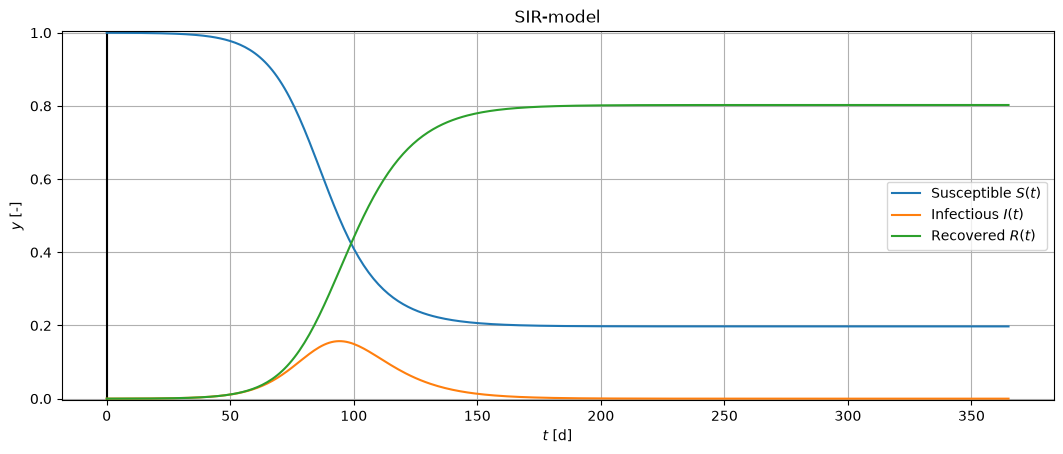

In [8]:
plot(*SIRmodel(beta=0.2))

Nu dit overgenomen en functionerend heb, kan makkelijk aan de hand van beta & gamma er veranderingen aangebracht worden.

18.666666666666668